# AI Cyber Threat Detection — Exploratory Notebook

**Project:** AI in Cyber Security Lab (ENSP355)  
**Dataset:** 4,000 **synthetic** login events (not real user logs)

This notebook walks through exploratory data analysis and compares three classifiers on the same held-out data. It is an educational demonstration, **not** a live security system.

## 1. Load the data

Open this notebook from the `notebooks/` folder with Jupyter. The code automatically locates the project root whether Jupyter starts there or in the repository's root directory.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "data" / "synthetic_login_events.csv").exists():
    ROOT = ROOT.parent
assert (ROOT / "data" / "synthetic_login_events.csv").exists(), "Open from the project root or notebooks/ folder"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

df = pd.read_csv(ROOT / "data" / "synthetic_login_events.csv")
print("Events:", len(df))
print("Suspicious share: {:.1f}%".format(100 * df["is_suspicious"].mean()))
display(df.head())

Events: 4000
Suspicious share: 27.3%


,event_id,hour,failed_attempts,login_velocity_10m,ip_reputation_score,geo_distance_km,new_device,mfa_used,is_weekend,login_channel,user_group,is_suspicious
0,EVT-000001,5,3,4,59.32,660.3,1,0,1,mobile,Group B,1
1,EVT-000002,17,2,2,51.98,36.8,0,0,0,web,Group A,0
2,EVT-000003,0,7,5,34.04,991.9,0,1,1,web,Group B,1
3,EVT-000004,16,0,2,64.04,311.2,1,1,0,mobile,Group A,0
4,EVT-000005,9,2,2,100.00,43.8,0,0,0,mobile,Group B,0


## 2. Understand the target classes

The target `is_suspicious` is **0** for normal and **1** for suspicious login events. The generator intentionally makes the dataset imbalanced.

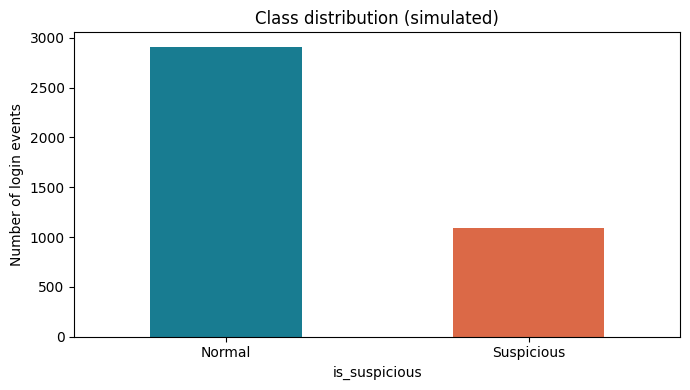

In [2]:
counts = df["is_suspicious"].value_counts().reindex([0, 1], fill_value=0)
ax = counts.plot(kind="bar", color=["#187C91", "#DB6947"], rot=0, figsize=(7, 4))
ax.set_xticklabels(["Normal", "Suspicious"])
ax.set_ylabel("Number of login events")
ax.set_title("Class distribution (simulated)")
plt.tight_layout()
plt.show()

## 3. Explore suspicious indicators

Look for differences in failed login attempts, login velocity, and IP reputation. A correlation or a visible separation does not prove an event is malicious.

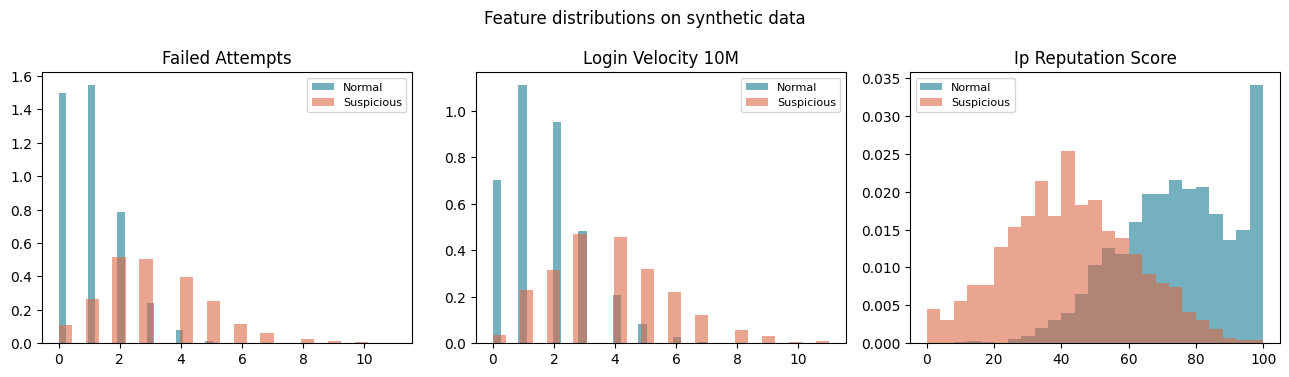

,failed_attempts,login_velocity_10m,ip_reputation_score
is_suspicious,,,
0,1.01,1.65,74.38
1,3.18,3.86,42.67


In [3]:
features = ["failed_attempts", "login_velocity_10m", "ip_reputation_score"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, feature in zip(axes, features):
    for label, color in [(0, "#187C91"), (1, "#DB6947")]:
        ax.hist(df.loc[df.is_suspicious == label, feature].dropna(), bins=25, density=True,
                alpha=0.6, label="Suspicious" if label else "Normal", color=color)
    ax.set_title(feature.replace("_", " ").title())
    ax.legend(fontsize=8)
fig.suptitle("Feature distributions on synthetic data")
plt.tight_layout()
plt.show()

display(df.groupby("is_suspicious")[features].mean().round(2))

## 4. Preprocessing and three models

All models use identical 75/25 stratified train/test indices. Missing values are imputed, numeric columns are standardized and categorical channels are one-hot encoded using a pipeline fitted only on the training set.

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from src.analyze import NUMERIC, CATEGORICAL, preprocessing
# Restore notebook backend because src.analyze uses Agg for script plots
%matplotlib inline

features = NUMERIC + CATEGORICAL
train_idx, test_idx = train_test_split(
    np.arange(len(df)), test_size=0.25, random_state=42, stratify=df["is_suspicious"]
)
train, test = df.iloc[train_idx], df.iloc[test_idx]
model_specs = {
    "Logistic Regression": LogisticRegression(max_iter=1500, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=10, random_state=42),
    "MLP Neural Network": MLPClassifier(hidden_layer_sizes=(32, 16), activation="relu",
                                         early_stopping=True, n_iter_no_change=15,
                                         max_iter=400, random_state=42),
}
trained_models, predicted_probabilities, rows = {}, {}, []
for name, classifier in model_specs.items():
    pipeline = Pipeline([("prepare", preprocessing()), ("classifier", classifier)])
    pipeline.fit(train[features], train["is_suspicious"])
    probabilities = pipeline.predict_proba(test[features])[:, 1]
    pred = (probabilities >= 0.5).astype(int)
    trained_models[name] = pipeline
    predicted_probabilities[name] = probabilities
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(test.is_suspicious, pred),
        "Precision": precision_score(test.is_suspicious, pred, zero_division=0),
        "Recall": recall_score(test.is_suspicious, pred, zero_division=0),
        "F1": f1_score(test.is_suspicious, pred, zero_division=0),
        "ROC AUC": roc_auc_score(test.is_suspicious, probabilities),
    })
display(pd.DataFrame(rows).round(3))

,Model,Accuracy,Precision,Recall,F1,ROC AUC
0,Logistic Regression,0.970,0.955,0.934,0.944,0.995
1,Decision Tree,0.940,0.893,0.886,0.889,0.970
2,MLP Neural Network,0.964,0.947,0.919,0.933,0.992


## 5. Visualize model errors

False positives are legitimate events incorrectly flagged as suspicious. False negatives are suspicious events the model misses.

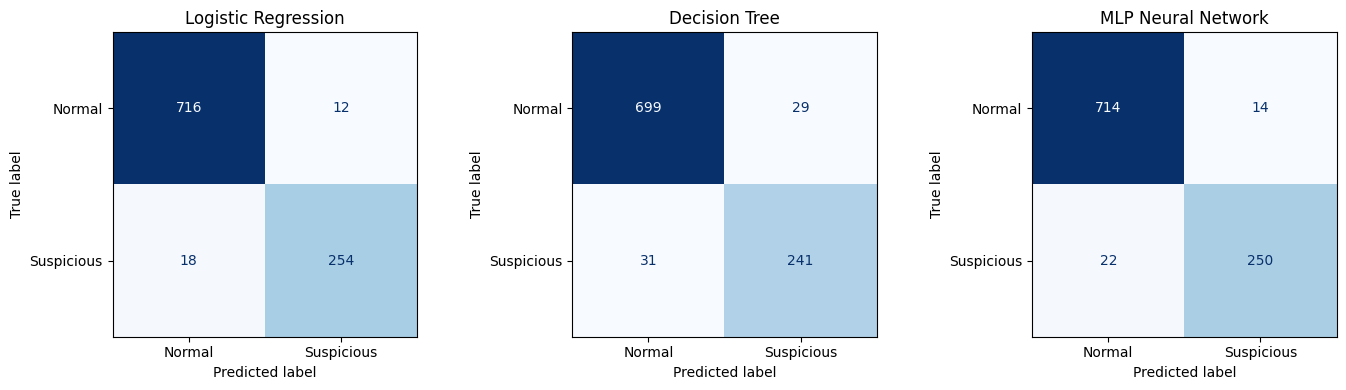

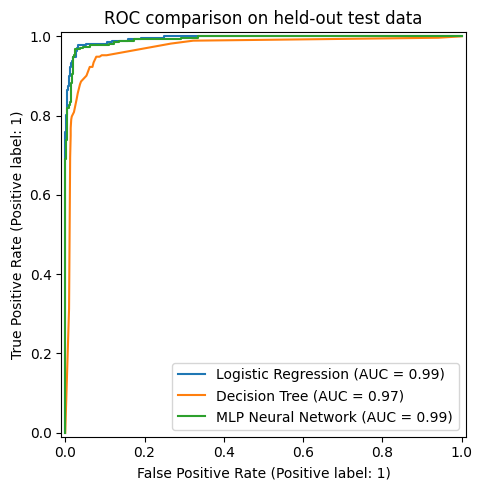

In [5]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, probabilities) in zip(axes, predicted_probabilities.items()):
    ConfusionMatrixDisplay.from_predictions(test.is_suspicious,
        (probabilities >= 0.5).astype(int), ax=ax, colorbar=False,
        display_labels=["Normal", "Suspicious"], cmap="Blues")
    ax.set_title(name)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
for name, probabilities in predicted_probabilities.items():
    RocCurveDisplay.from_predictions(test.is_suspicious, probabilities, name=name, ax=ax)
ax.set_title("ROC comparison on held-out test data")
plt.tight_layout()
plt.show()

## 6. Ethical analysis: thresholds and biased labels

These results are produced by `run_project.py`. Changing a threshold trades off false alarms against missed attacks. The separate bias experiment deliberately mislabels legitimate synthetic Group B examples during training; it does not represent any real demographic group.

In [6]:
threshold_file = ROOT / "outputs" / "threshold_analysis.csv"
fairness_file = ROOT / "outputs" / "fairness_analysis.csv"
if not threshold_file.exists() or not fairness_file.exists():
    raise FileNotFoundError("Run 'python run_project.py' in the project root first.")
thresholds = pd.read_csv(threshold_file)
fairness = pd.read_csv(fairness_file)
print("Threshold tradeoff")
display(thresholds[["threshold", "false_positive", "false_negative", "recall"]].round(3))
print("Fairness simulation")
display(fairness[["training_condition", "group", "benign_events", "false_positives", "false_positive_rate"]].round(3))

Threshold tradeoff


,threshold,false_positive,false_negative,recall
0,0.3,21,8,0.971
1,0.5,12,18,0.934
2,0.7,6,32,0.882


Fairness simulation


,training_condition,group,benign_events,false_positives,false_positive_rate
0,Original labels,Group A,374,8,0.021
1,Original labels,Group B,354,4,0.011
2,Biased training labels,Group A,374,3,0.008
3,Biased training labels,Group B,354,133,0.376


## 7. Observations and limitations

- Compare **precision, recall and F1**, not accuracy alone, because the dataset is imbalanced.
- A Decision Tree provides an interpretable non-linear baseline but is not automatically more accurate than a linear model or MLP.
- Changing the alert threshold affects legitimate users as well as detection sensitivity.
- The data are artificially generated with known patterns. Strong metrics here **do not establish real-world cybersecurity effectiveness**.
- An actual deployment would need authorized real-world validation, robust access controls, monitoring for drift, explainability, and human review.

See `report/technical_report.pdf` for the full report.